# 4 Наивный байесовский классификатор

In [9]:
#!/usr/bin/env python3

import numpy as np
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB

from utilities import visualize_classifier

In [10]:
# Входной файл, содержащий данные
input_file = 'data/data_multivar_nb.txt'
# Загрузка данных из входного файла
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

In [11]:
# Создание наивного байесовского классификатора
classifier = GaussianNB()
# Тренировка классификатора
classifier.fit(X, y)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](4,)","[100.,100.,100.,100.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](4,)","[0.25,0.25,0.25,0.25]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[float64](4,)","[0.,1.,2.,3.]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,7.266e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](4, 2)","[[ 1.22, 1.46], [ 4.94, 5.96], [ 8.46, 2.39], [ 4.45,-1.23]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](4, 2)","[[0.48,0.6 ], [0.65,0.63], [0.63,0.72], [0.47,0.6 ]]"


Accuracy of Naive Bayes classifier = 99.75 %


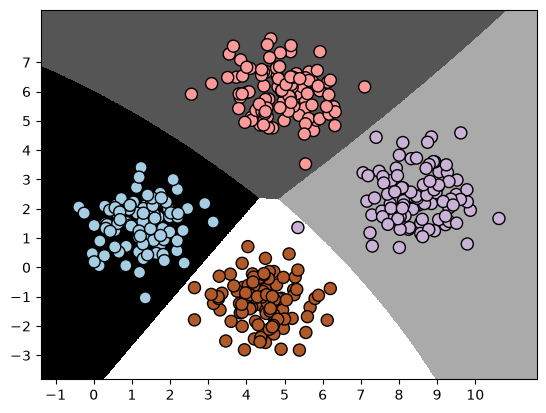

In [12]:
# Прогнозирование значений для тренировочных данных
y_pred = classifier.predict(X)
# Вычисление качества классификатора
accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")
# Визуализация результатов работы классификатора
visualize_classifier(classifier, X, y)

In [13]:
# Разбивка данных на обучающий и тестовый наборы
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)
classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)

Accuracy of the new classifier = 100.0 %


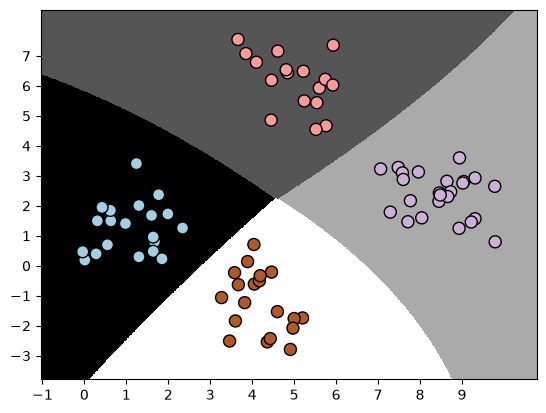

In [14]:
# Вычисление качества классификатора
accuracy = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy, 2), "%")
# Визуализация работы классификатора
visualize_classifier(classifier_new, X_test, y_test)

In [16]:
# Оценка показателей классификатора
print("Оценка показателей классификатора")
num_folds = 3
accuracy_values = cross_val_score(classifier, X, y, scoring='accuracy', cv=num_folds)
print("Accuracy: " + str(round(100*accuracy_values.mean(), 2)) + "%")
precision_values = cross_val_score(classifier,
X, y, scoring='precision_weighted', cv=num_folds)
print("Precision: " + str(round(100*precision_values.mean(), 2)) + "%")
recall_values = cross_val_score(classifier,
X, y, scoring='recall_weighted', cv=num_folds)
print("Recall: " + str(round(100*recall_values.mean(), 2)) + "%")
f1_values = cross_val_score(classifier,
X, y, scoring='f1_weighted', cv=num_folds)
print("F1: " + str(round(100*f1_values.mean(), 2)) + "%")

Оценка показателей классификатора
Accuracy: 99.75%
Precision: 99.76%
Recall: 99.75%
F1: 99.75%
